In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
PROJECT_ROOT = Path.cwd().parent          # notebooks/ -> market-analyzer/
df = pd.read_parquet(PROJECT_ROOT / "data/processed/listings_clean.parquet")
print(f"Shape: {df.shape}")
print(f"Columns: {len(df.columns)}")

Shape: (16558, 94)
Columns: 94


In [2]:
df[["price", "accommodates", "bedrooms", "bathrooms",
    "amenity_count", "distance_to_center_km"]].describe()

,price,accommodates,bedrooms,amenity_count,distance_to_center_km
count,"16,558.00","16,558.00","16,553.00","16,558.00","16,558.00"
mean,"6,321.84",3.73,1.46,33.42,7.53
std,"10,311.44",2.26,1.16,15.28,10.71
min,320.00,1.00,0.00,0.00,0.04
25%,"3,000.00",2.00,1.00,23.00,2.65
50%,"4,469.75",3.00,1.00,34.00,3.76
75%,"6,856.57",4.00,2.00,44.00,6.66
max,"502,353.28",16.00,50.00,97.00,81.19


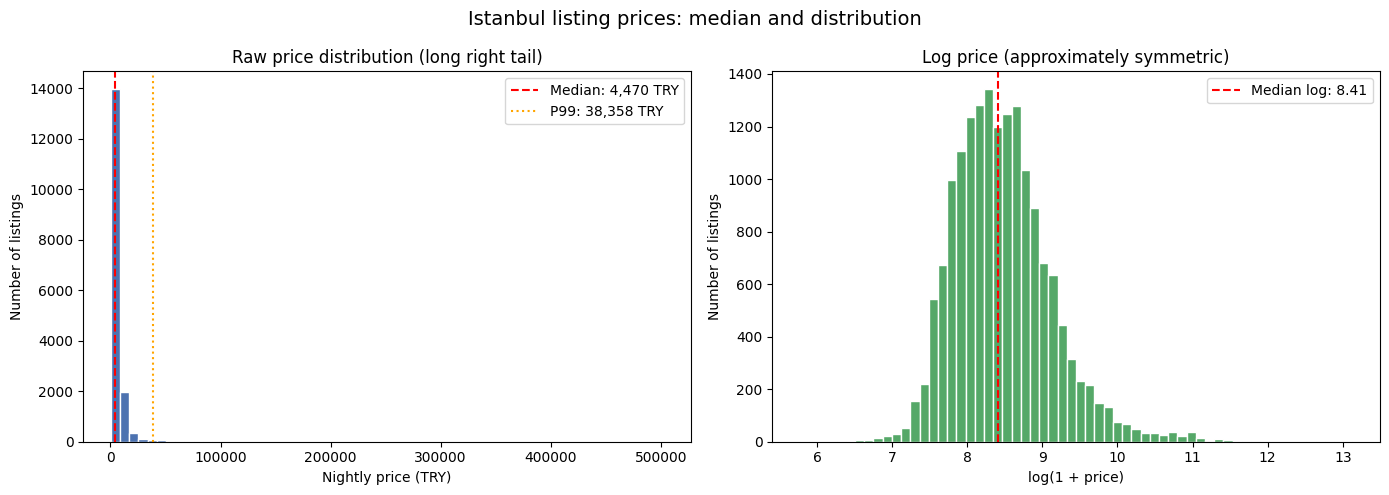

In [6]:
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent          # notebooks/ -> market-analyzer/
out_path = PROJECT_ROOT / "reports/eda/price_distribution.png"
out_path.parent.mkdir(parents=True, exist_ok=True)   # create reports/eda/ if missing
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Left panel: raw price ----
axes[0].hist(df["price"], bins=60, color="#4C72B0", edgecolor="white")
axes[0].axvline(df["price"].median(), color="red", linestyle="--",
                label=f"Median: {df['price'].median():,.0f} TRY")
axes[0].axvline(df["price"].quantile(0.99), color="orange", linestyle=":",
                label=f"P99: {df['price'].quantile(0.99):,.0f} TRY")
axes[0].set_xlabel("Nightly price (TRY)")
axes[0].set_ylabel("Number of listings")
axes[0].set_title("Raw price distribution (long right tail)")
axes[0].legend()

# ---- Right panel: log price ----
axes[1].hist(df["price_log"], bins=60, color="#55A868", edgecolor="white")
axes[1].axvline(df["price_log"].median(), color="red", linestyle="--",
                label=f"Median log: {df['price_log'].median():.2f}")
axes[1].set_xlabel("log(1 + price)")
axes[1].set_ylabel("Number of listings")
axes[1].set_title("Log price (approximately symmetric)")
axes[1].legend()

fig.suptitle("Istanbul listing prices: median and distribution", fontsize=14)
fig.tight_layout()


fig.savefig(out_path, dpi=160, bbox_inches="tight")
plt.show()

In [9]:
print(df['price'].quantile(0.25))


3000.0


In [10]:
print(df['price'].quantile(0.75))

6856.5675


In [12]:
print(df['price'].max())

502353.28
